# Lab 2 — Anomaly detection practice: stolen account

Scenario: the account of a normal user (User) is stolen and used by an attacker.
This matches MITRE ATT&CK **T1078 — Valid Accounts** (the attacker logs in with a real account) and **T1110 — Brute Force** (a few failed attempts before success).

The attacker is **not** an obvious foreigner. He logs in from Israel, and **every value he can produce can also be produced by User**: both are generated by the same function, from the same lists of cities, devices, browsers and ISPs. Only the **probabilities** are a little different (a medium shift). No single value proves an attack, so the models must find unusual *combinations* and *frequencies*.

All values are random draws from probability distributions (normal, Poisson, gamma, weighted choices) with NumPy, and realistic dates and IP addresses come from the **Faker** library.

## Step 1 — Create the normal user data

User lives in Tel Aviv and works in Ramat Gan. One function, `generate_logins(n, profile)`, creates the logins; a **profile** holds the probabilities.

| column | how it is generated |
|---|---|
| `hour` | normal distribution (mean, std from the profile), rounded, clipped to 0-23 |
| `is_weekend` | Bernoulli: Friday / Saturday with probability `p_weekend` |
| `timestamp` | Faker date (May-Oct 2026) that matches `is_weekend`, + the hour and a random minute |
| `city` | weighted choice from 12 Israeli cities |
| `distance_km` | haversine distance from User's home + gamma noise (geo-IP error) |
| `failed_attempts` | Poisson distribution |
| `device` | weighted choice: MacBook, iPhone, Windows, Android |
| `browser` | weighted choice that depends on the device (Safari only on Apple devices) |
| `isp` | with probability `p_usual_isp` the ISP User normally has in that place (office = Partner, home = Bezeq, Herzliya = HOT, phone = Cellcom), otherwise a weighted random ISP |
| `ip_address` | Faker address inside an Israeli-like range of that ISP; User re-uses one of her known IPs with probability `p_known_ip` (display only, not a model feature) |

In [26]:
%pip install -q faker

Note: you may need to restart the kernel to use updated packages.


In [2]:
import ipaddress
import numpy as np
import pandas as pd
from datetime import date, datetime, time
from faker import Faker

n_normal = 1000
n_attack = 40

rng = np.random.default_rng(50)
Faker.seed(50)
fake = Faker()

# ---- Shared value lists: User and attacker draw from the SAME lists ----
cities = {   # (latitude, longitude)
    "Tel Aviv": (32.0853, 34.7818), "Ramat Gan": (32.0684, 34.8248), "Herzliya": (32.1624, 34.8447),
    "Holon": (32.0158, 34.7874), "Petah Tikva": (32.0840, 34.8878), "Rishon LeZion": (31.9730, 34.7925),
    "Kfar Saba": (32.1750, 34.9070), "Netanya": (32.3215, 34.8532), "Ashdod": (31.8044, 34.6553),
    "Jerusalem": (31.7683, 35.2137), "Haifa": (32.7940, 34.9896), "Be'er Sheva": (31.2518, 34.7913),
}
devices = ["MacBook", "iPhone", "Windows", "Android"]
browsers = ["Safari", "Chrome", "Firefox", "Edge"]
isp_networks = {   # illustrative Israeli-like address ranges, one per ISP
    "Bezeq": "79.176.0.0/13", "HOT": "89.138.0.0/15", "Partner": "85.64.0.0/15",
    "Cellcom": "77.124.0.0/14", "Pelephone": "37.142.0.0/16", "Golan Telecom": "5.28.0.0/16",
}
isps = list(isp_networks)

HOME = cities["Tel Aviv"]
usual_isp = {"Ramat Gan": "Partner", "Tel Aviv": "Bezeq", "Herzliya": "HOT"}   # User's routine
MOBILE_ISP = "Cellcom"                                                          # User's phone plan

def pick(weights, size, rng=rng):
    """Random choice with probabilities. weights = {value: probability}"""
    p = np.array(list(weights.values()), dtype=float)
    return rng.choice(list(weights), size=size, p=p / p.sum())

def distance_from_home(city_names, rng=rng):
    """Haversine distance from User's home + geo-IP noise (gamma distribution)."""
    lat1, lon1 = np.radians(HOME)
    lat2 = np.radians([cities[c][0] for c in city_names])
    lon2 = np.radians([cities[c][1] for c in city_names])
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    km = 2 * 6371 * np.arcsin(np.sqrt(a))
    return np.round(km + rng.gamma(shape=2.0, scale=1.5, size=len(city_names))).astype(int)

def random_ip(isp):
    """Faker picks a random address inside the ISP's range."""
    net = ipaddress.ip_network(isp_networks[isp])
    return str(net[fake.random_int(1, net.num_addresses - 2)])

known_ips = {isp: [random_ip(isp) for _ in range(3)] for isp in isps}   # User's routers / phone

def make_ips(isp_values, p_known, rng=rng):
    out = []
    for isp in isp_values:
        if isp in known_ips and rng.random() < p_known:
            out.append(str(rng.choice(known_ips[isp])))   # an IP User used before
        elif isp in isp_networks:
            out.append(random_ip(isp))                    # new IP from an Israeli ISP
        else:
            out.append(fake.ipv4_public())                # abroad
    return out

def make_timestamps(hours, is_weekend):
    """Faker date (May-Oct 2026) with the right weekday type, plus the given hour."""
    out = []
    for h, weekend in zip(hours, is_weekend):
        while True:
            d = fake.date_between(start_date=date(2026, 5, 1), end_date=date(2026, 10, 31))
            if (d.weekday() in (4, 5)) == bool(weekend):      # Friday / Saturday = Israeli weekend
                break
        out.append(datetime.combine(d, time(int(h), fake.random_int(0, 59))))
    return out

def generate_logins(n, profile, rng=rng):
    """Same code for User and attacker - only the probabilities in `profile` differ."""
    hour = np.clip(np.round(rng.normal(profile["hour_mean"], profile["hour_std"], n)), 0, 23).astype(int)
    is_weekend = (rng.random(n) < profile["p_weekend"]).astype(int)
    city = pick(profile["city"], n, rng)
    device = pick(profile["device"], n, rng)
    apple = np.isin(device, ["MacBook", "iPhone"])
    browser = np.where(apple, pick(profile["browser_apple"], n, rng), pick(profile["browser_other"], n, rng))
    usual = np.array([MOBILE_ISP if d in ("iPhone", "Android") else usual_isp.get(c, "")
                      for c, d in zip(city, device)])
    random_isp = pick(profile["isp"], n, rng)
    isp = np.where((usual != "") & (rng.random(n) < profile["p_usual_isp"]), usual, random_isp)
    return pd.DataFrame({
        "timestamp": make_timestamps(hour, is_weekend),
        "hour": hour,
        "is_weekend": is_weekend,
        "distance_km": distance_from_home(city, rng),
        "failed_attempts": rng.poisson(profile["failed_mean"], n),
        "country": "IL",
        "city": city,
        "device": device,
        "browser": browser,
        "isp": isp,
        "ip_address": make_ips(isp, profile["p_known_ip"], rng),
    })

#User
user_profile = {
    "hour_mean": 12.5, "hour_std": 2.0,
    "p_weekend": 0.05,
    "city": {"Ramat Gan": 0.50, "Tel Aviv": 0.33, "Herzliya": 0.07, "Holon": 0.015, "Petah Tikva": 0.015,
             "Jerusalem": 0.015, "Rishon LeZion": 0.01, "Kfar Saba": 0.01, "Netanya": 0.01, "Haifa": 0.01,
             "Ashdod": 0.005, "Be'er Sheva": 0.005},
    "failed_mean": 0.3,
    "device": {"MacBook": 0.78, "iPhone": 0.17, "Windows": 0.03, "Android": 0.02},
    "browser_apple": {"Safari": 0.62, "Chrome": 0.33, "Firefox": 0.03, "Edge": 0.02},
    "browser_other": {"Chrome": 0.80, "Firefox": 0.10, "Edge": 0.10},
    "p_usual_isp": 0.85,
    "isp": {"Bezeq": 0.25, "HOT": 0.25, "Partner": 0.20, "Cellcom": 0.20, "Pelephone": 0.05, "Golan Telecom": 0.05},
    "p_known_ip": 0.90,
}
user = generate_logins(n_normal, user_profile)
user["is_attack"] = 0

print("hour:", user["hour"].value_counts().sort_index().to_dict())
print("distance_km min / median / max:", user["distance_km"].min(), user["distance_km"].median(), user["distance_km"].max())
print("failed_attempts:", user["failed_attempts"].value_counts().sort_index().to_dict())
for col in ["city", "device", "browser", "isp"]:
    print(col, user[col].value_counts().to_dict())

hour: {6: 2, 7: 5, 8: 9, 9: 38, 10: 95, 11: 157, 12: 184, 13: 196, 14: 169, 15: 76, 16: 44, 17: 18, 18: 6, 20: 1}
distance_km min / median / max: 0 7.0 97
failed_attempts: {0: 718, 1: 232, 2: 44, 3: 6}
city {'Ramat Gan': 497, 'Tel Aviv': 321, 'Herzliya': 72, 'Jerusalem': 19, 'Holon': 17, 'Haifa': 17, 'Petah Tikva': 15, 'Rishon LeZion': 13, 'Kfar Saba': 9, 'Netanya': 9, 'Ashdod': 6, "Be'er Sheva": 5}
device {'MacBook': 769, 'iPhone': 182, 'Windows': 32, 'Android': 17}
browser {'Safari': 565, 'Chrome': 383, 'Firefox': 30, 'Edge': 22}
isp {'Partner': 392, 'Bezeq': 269, 'Cellcom': 211, 'HOT': 110, 'Golan Telecom': 11, 'Pelephone': 7}


Now the attacker. He uses User's stolen password from inside Israel and is generated by the **same function**, so every value he can have, User can have too. Only the probabilities are shifted:

| parameter | User | attacker |
|---|---|---|
| `hour` | Normal(12.5, 2) | Normal(15, 4) → often normal hours, sometimes early / late |
| `p_weekend` | 5% | 25% |
| `city` | Ramat Gan 50%, Tel Aviv 33%, Herzliya 7%, other 9 cities 10% | spread over all 12 cities (Tel Aviv 20%, Ramat Gan 12%, ...) |
| `failed_attempts` | Poisson(0.3) | Poisson(1.3) |
| `device` | MacBook 78%, iPhone 17%, Windows 3%, Android 2% | MacBook 40%, iPhone 15%, Windows 30%, Android 15% |
| `browser` (Apple) | Safari 62%, Chrome 33%, Firefox 3%, Edge 2% | Safari 35%, Chrome 45%, Firefox 12%, Edge 8% |
| `browser` (other) | Chrome 80%, Firefox 10%, Edge 10% | Chrome 60%, Firefox 20%, Edge 20% |
| `p_usual_isp` | 85% | 15% (only by chance) |
| random `isp` | Pelephone 5%, Golan 5%, others 90% | Pelephone 20%, Golan 25%, others 55% |
| `p_known_ip` | 90% | 0% (always a new IP) |

In [3]:
#Attacker
attacker_profile = {
    "hour_mean": 15.0, "hour_std": 4.0,
    "p_weekend": 0.25,
    "city": {"Tel Aviv": 0.20, "Ramat Gan": 0.12, "Herzliya": 0.05, "Holon": 0.09, "Petah Tikva": 0.10,
             "Jerusalem": 0.10, "Rishon LeZion": 0.08, "Kfar Saba": 0.05, "Netanya": 0.08, "Haifa": 0.05,
             "Ashdod": 0.05, "Be'er Sheva": 0.03},
    "failed_mean": 1.3,
    "device": {"MacBook": 0.40, "iPhone": 0.15, "Windows": 0.30, "Android": 0.15},
    "browser_apple": {"Safari": 0.35, "Chrome": 0.45, "Firefox": 0.12, "Edge": 0.08},
    "browser_other": {"Chrome": 0.60, "Firefox": 0.20, "Edge": 0.20},
    "p_usual_isp": 0.15,
    "isp": {"Bezeq": 0.15, "HOT": 0.15, "Partner": 0.10, "Cellcom": 0.15, "Pelephone": 0.20, "Golan Telecom": 0.25},
    "p_known_ip": 0.0,
}
attacker = generate_logins(n_attack, attacker_profile)
attacker["is_attack"] = 1

print("hours:", sorted(attacker["hour"].tolist()))
print("distance_km:", sorted(attacker["distance_km"].tolist()))
print("failed_attempts:", sorted(attacker["failed_attempts"].tolist()))
for col in ["device", "browser", "isp"]:
    print(col, attacker[col].value_counts().to_dict())

hours: [5, 6, 7, 9, 10, 10, 10, 11, 11, 11, 12, 12, 13, 13, 13, 13, 13, 14, 14, 14, 15, 15, 15, 16, 16, 16, 16, 17, 17, 17, 18, 18, 18, 19, 19, 20, 21, 21, 23, 23]
distance_km: [1, 2, 2, 2, 3, 3, 3, 5, 5, 5, 5, 10, 10, 11, 11, 12, 12, 12, 13, 13, 13, 14, 14, 15, 19, 20, 20, 28, 31, 35, 37, 55, 56, 57, 57, 58, 83, 83, 95, 97]
failed_attempts: [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 3, 3, 3, 3, 4, 5]
device {'MacBook': 16, 'Windows': 10, 'iPhone': 9, 'Android': 5}
browser {'Chrome': 23, 'Firefox': 7, 'Safari': 6, 'Edge': 4}
isp {'Golan Telecom': 10, 'Pelephone': 7, 'HOT': 7, 'Bezeq': 6, 'Partner': 6, 'Cellcom': 4}


Look at the two tables side by side. `country` is IL for everybody. `is_attack` is the label (used only for evaluation). `timestamp` and `ip_address` are kept for the analyst, but the models do not use them.

The share table shows that no category belongs to only one class — the classes differ only in how **often** each value appears.

In [4]:
print(user.head())
print(attacker.head())

for col in ["city", "device", "browser", "isp"]:
    share = pd.DataFrame({"user": user[col].value_counts(normalize=True),
                          "attacker": attacker[col].value_counts(normalize=True)}).fillna(0).round(3)
    print(share.sort_values("user", ascending=False), "\n")

            timestamp  hour  is_weekend  distance_km  failed_attempts country  \
0 2026-09-29 13:22:00    13           0            3                0      IL   
1 2026-10-24 12:44:00    12           1           14                0      IL   
2 2026-08-19 14:21:00    14           0            8                1      IL   
3 2026-09-23 10:41:00    10           0            4                0      IL   
4 2026-09-30 16:00:00    16           0            1                1      IL   

        city   device browser      isp      ip_address  is_attack  
0   Tel Aviv  MacBook  Safari    Bezeq  79.182.216.119          0  
1   Herzliya   iPhone  Safari  Cellcom   77.127.26.143          0  
2  Ramat Gan  MacBook  Safari  Partner    85.64.242.68          0  
3   Tel Aviv  MacBook  Chrome    Bezeq    79.178.33.32          0  
4   Tel Aviv  MacBook  Safari  Partner    85.64.242.68          0  
            timestamp  hour  is_weekend  distance_km  failed_attempts country  \
0 2026-07-24 17:23:00   

Join the two tables and shuffle the rows.

In [5]:
numeric_cols = ["hour", "is_weekend", "distance_km", "failed_attempts"]
categorical_cols = ["country", "city", "device", "browser", "isp"]
info_cols = ["timestamp", "ip_address"]      # for the analyst only, not model features

df = pd.concat([user, attacker], ignore_index=True)
df = df.sample(frac=1, random_state=42).reset_index(drop=True)
print(df.shape)
print(df["is_attack"].value_counts())

(1040, 12)
is_attack
0    1000
1      40
Name: count, dtype: int64


## Step 2 — EDA (exploratory data analysis)

Check the size, data types, missing values, infinite values and the share of attacks.

In [6]:
print(df.shape)
print(df.dtypes)
print(df.isna().sum())
print(df["is_attack"].value_counts(normalize=True))
print(np.isinf(df[numeric_cols]).sum())

(1040, 12)
timestamp          datetime64[us]
hour                        int64
is_weekend                  int64
distance_km                 int64
failed_attempts             int64
country                       str
city                          str
device                        str
browser                       str
isp                           str
ip_address                    str
is_attack                   int64
dtype: object
timestamp          0
hour               0
is_weekend         0
distance_km        0
failed_attempts    0
country            0
city               0
device             0
browser            0
isp                0
ip_address         0
is_attack          0
dtype: int64
is_attack
0    0.961538
1    0.038462
Name: proportion, dtype: float64
hour               0
is_weekend         0
distance_km        0
failed_attempts    0
dtype: int64


Histogram of `distance_km` for normal and attack rows (log scale), plus min / median / max per class, and how often each category appears in each class.

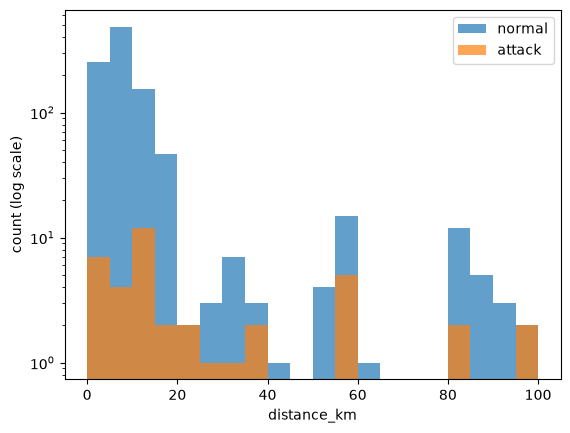

          hour            is_weekend            distance_km             \
           min median max        min median max         min median max   
is_attack                                                                
0            6   13.0  20          0    0.0   1           0    7.0  97   
1            5   14.5  23          0    0.0   1           1   13.0  97   

          failed_attempts             
                      min median max  
is_attack                             
0                       0    0.0   3  
1                       0    1.0   5  
is_attack         0     1
city                     
Ashdod         0.01  0.02
Be'er Sheva    0.00  0.05
Haifa          0.02  0.05
Herzliya       0.07  0.00
Holon          0.02  0.12
Jerusalem      0.02  0.12
Kfar Saba      0.01  0.08
Netanya        0.01  0.08
Petah Tikva    0.02  0.08
Ramat Gan      0.50  0.08
Rishon LeZion  0.01  0.12
Tel Aviv       0.32  0.20
is_attack     0     1
device               
Android    0.02  0.12
MacB

In [7]:
import matplotlib.pyplot as plt

bins = np.arange(0, df["distance_km"].max() + 5, 5)

plt.hist(df[df["is_attack"] == 0]["distance_km"], bins=bins, alpha=0.7, label="normal")
plt.hist(df[df["is_attack"] == 1]["distance_km"], bins=bins, alpha=0.7, label="attack")
plt.yscale("log")
plt.xlabel("distance_km")
plt.ylabel("count (log scale)")
plt.legend()
plt.show()
print(df.groupby("is_attack")[numeric_cols].agg(["min", "median", "max"]))
for col in ["city", "device", "browser", "isp"]:
    print(pd.crosstab(df[col], df["is_attack"], normalize="columns").round(2))

**Normal behaviour:** The user logs in from Israel (IL) on her MacBook during working hours (09:00-17:00, median 13:00). She connects from close to her usual location (0-9 km, median 5 km) and makes very few failed attempts (0-2, median 1).

**Suspicious behaviour:** The attacker logs in from Pakistan (PK) on a Linux machine, at night (00:00-05:00, median 02:00). The connection comes from thousands of km away (about 3,076-8,763 km, median 5,822 km) and is preceded by many failed attempts (6-15, median 10).

**Best separating features:** In this synthetic dataset, all three numeric features (`hour`, `distance_km`, `failed_attempts`) have non-overlapping ranges between the two groups. `distance_km` shows the largest gap (9 km for normal vs. at least 3,076 km for attacks), so it separates the classes most clearly. This is unrealistically easy; in real data, ranges would overlap (for example a legitimate user travelling abroad).

Histogram of the login hour for normal and attack rows.

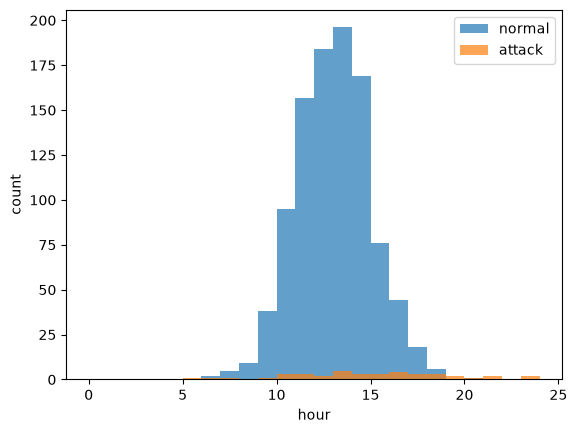

hour               0
distance_km        0
failed_attempts    0
dtype: int64


In [8]:
bins = np.arange(0, 25)

plt.hist(df[df["is_attack"] == 0]["hour"], bins=bins, alpha=0.7, label="normal")
plt.hist(df[df["is_attack"] == 1]["hour"], bins=bins, alpha=0.7, label="attack")
plt.xlabel("hour")
plt.ylabel("count")
plt.legend()
plt.show()
print(np.isinf(df[["hour", "distance_km", "failed_attempts"]]).sum())

Example of one-hot encoding: `country`, `city`, `device`, `browser` and `isp` become 0/1 columns (`timestamp` and `ip_address` are dropped).

In [9]:
encoded = pd.get_dummies(df.drop(columns=info_cols), columns=categorical_cols)
print(encoded.head())
print(encoded.columns)

   hour  is_weekend  distance_km  failed_attempts  is_attack  country_IL  \
0    14           0            2                1          0        True   
1    13           0           16                0          0        True   
2    13           0           11                1          0        True   
3    13           0            8                1          0        True   
4    13           0            6                0          0        True   

   city_Ashdod  city_Be'er Sheva  city_Haifa  city_Herzliya  ...  \
0        False             False       False          False  ...   
1        False             False       False          False  ...   
2        False             False       False          False  ...   
3        False             False       False          False  ...   
4        False             False       False          False  ...   

   browser_Chrome  browser_Edge  browser_Firefox  browser_Safari  isp_Bezeq  \
0            True         False            False       

Scale all features with `StandardScaler` (mean 0, standard deviation 1), so that `distance_km` does not dominate only because its numbers are big.

In [10]:
from sklearn.preprocessing import StandardScaler

features = encoded.drop(columns=["is_attack"])
scaler = StandardScaler()
scaled = scaler.fit_transform(features)

print(scaled[:3])
print(scaled.shape)

[[ 0.64438846 -0.2847474  -0.55598163  0.95507398  0.         -0.08231877
  -0.08231877 -0.13641557 -0.27272727 -0.14700681 -0.15369466 -0.10804236
  -0.10804236 -0.13271219 -0.96225045 -0.13271219  1.47006606 -0.14700681
   0.56994804 -0.20514426 -0.47431061  1.24963049 -0.16012815 -0.19206596
  -1.10339658  1.66787835 -0.5104959  -0.1435564  -0.3560345  -0.78736122
  -0.11681277]
 [ 0.17931976 -0.2847474   0.36162124 -0.57539896  0.         -0.08231877
  -0.08231877 -0.13641557 -0.27272727 -0.14700681 -0.15369466 -0.10804236
  -0.10804236 -0.13271219 -0.96225045  7.53510304 -0.68024154 -0.14700681
   0.56994804 -0.20514426 -0.47431061 -0.80023656  6.244998   -0.19206596
  -1.10339658 -0.59956411 -0.5104959  -0.1435564  -0.3560345   1.27006509
  -0.11681277]
 [ 0.17931976 -0.2847474   0.03390593  0.95507398  0.         -0.08231877
  -0.08231877 -0.13641557 -0.27272727 -0.14700681 -0.15369466 -0.10804236
  -0.10804236 -0.13271219  1.03923048 -0.13271219 -0.68024154 -0.14700681
   0.569

First Isolation Forest run. Note: here the model is trained and tested on the **same** rows, so the result is too optimistic. The next steps add realistic noise and a proper train / test split.

In [11]:
from sklearn.ensemble import IsolationForest
from sklearn.metrics import confusion_matrix, classification_report

iso = IsolationForest(n_estimators=100, contamination=0.04, random_state=42)
iso.fit(scaled)

pred = (iso.predict(scaled) == -1).astype(int)
y = df["is_attack"]

print("flagged as anomaly:", pred.sum())
print(confusion_matrix(y, pred))
print(classification_report(y, pred, target_names=["Normal", "Attack"]))

flagged as anomaly: 42
[[986  14]
 [ 12  28]]
              precision    recall  f1-score   support

      Normal       0.99      0.99      0.99      1000
      Attack       0.67      0.70      0.68        40

    accuracy                           0.97      1040
   macro avg       0.83      0.84      0.83      1040
weighted avg       0.98      0.97      0.98      1040



## Step 3 — Make the data harder

Real data has even more overlap. We change the same data with a fixed seed (42):

**Legitimate exceptions of User (about 7% of normal rows)** — each one changes only one or two things:
- `late_work` (2%): she works late, `hour` 19-22.
- `trip_in_israel` (2%): visiting Jerusalem / Haifa / Be'er Sheva, on mobile data (`isp` = Cellcom).
- `forgot_password` (2%): 3-5 `failed_attempts` before success.
- `business_trip` (1%): abroad (GR or CY), 500-2000 km, MacBook + Safari in working hours.

**Mimic attacks (about 25% of attacks):** the attacker copies User's habits — MacBook, Safari / Chrome, working hours on a weekday, Tel Aviv / Ramat Gan, 0-1 failed attempts. Only the ISP and the (new) IP address may still be different, and sometimes even the ISP is one User uses.

After every change, `timestamp` and `ip_address` are generated again, so they stay consistent with `hour`, `is_weekend` and `isp`.

The columns stay the same. The kind of row (`scenario`) is kept in a separate variable only to explain results later; the models never see it.

In [12]:
rng = np.random.default_rng(42)

user_hard = user.copy()
attacker_hard = attacker.copy()
user_hard["scenario"] = "normal"
attacker_hard["scenario"] = "attack"

def refresh(frame, idx, p_known):
    """Generate timestamp and IP again, so they match the changed hour / weekend / ISP."""
    frame.loc[idx, "timestamp"] = make_timestamps(frame.loc[idx, "hour"], frame.loc[idx, "is_weekend"])
    frame.loc[idx, "ip_address"] = make_ips(frame.loc[idx, "isp"], p_known, rng)

# Legitimate exceptions: each normal row gets at most one
exceptions = {"late_work": 0.02, "trip_in_israel": 0.02, "forgot_password": 0.02, "business_trip": 0.01}
free_idx = user_hard.index.to_numpy()
for name, share in exceptions.items():
    n = int(round(share * len(user_hard)))
    idx = rng.choice(free_idx, size=n, replace=False)
    free_idx = np.setdiff1d(free_idx, idx)
    user_hard.loc[idx, "scenario"] = name
    if name == "late_work":
        user_hard.loc[idx, "hour"] = rng.integers(19, 23, size=n)
    elif name == "trip_in_israel":
        trip_city = pick({"Jerusalem": 0.4, "Haifa": 0.4, "Be'er Sheva": 0.2}, n, rng=rng)
        user_hard.loc[idx, "city"] = trip_city
        user_hard.loc[idx, "distance_km"] = distance_from_home(trip_city, rng=rng)
        user_hard.loc[idx, "isp"] = MOBILE_ISP
    elif name == "forgot_password":
        user_hard.loc[idx, "failed_attempts"] = rng.integers(3, 6, size=n)
    elif name == "business_trip":
        user_hard.loc[idx, "country"] = rng.choice(["GR", "CY"], size=n)
        user_hard.loc[idx, "city"] = "abroad"
        user_hard.loc[idx, "distance_km"] = rng.integers(500, 2001, size=n)
        user_hard.loc[idx, "device"] = "MacBook"
        user_hard.loc[idx, "browser"] = "Safari"
        user_hard.loc[idx, "isp"] = "Foreign ISP"
        user_hard.loc[idx, "hour"] = rng.integers(9, 18, size=n)
    refresh(user_hard, idx, p_known=user_profile["p_known_ip"])

# Mimic attacks: about 25% of attack rows copy User's habits
n_mimic = int(round(0.25 * len(attacker_hard)))
mimic_idx = rng.choice(attacker_hard.index, size=n_mimic, replace=False)
mimic_city = pick({"Tel Aviv": 0.5, "Ramat Gan": 0.5}, n_mimic, rng=rng)
attacker_hard.loc[mimic_idx, "hour"] = np.clip(np.round(rng.normal(12.5, 2.0, n_mimic)), 8, 18).astype(int)
attacker_hard.loc[mimic_idx, "is_weekend"] = 0
attacker_hard.loc[mimic_idx, "city"] = mimic_city
attacker_hard.loc[mimic_idx, "distance_km"] = distance_from_home(mimic_city, rng=rng)
attacker_hard.loc[mimic_idx, "failed_attempts"] = rng.integers(0, 2, size=n_mimic)
attacker_hard.loc[mimic_idx, "device"] = "MacBook"
attacker_hard.loc[mimic_idx, "browser"] = pick({"Safari": 0.6, "Chrome": 0.4}, n_mimic, rng=rng)
attacker_hard.loc[mimic_idx, "scenario"] = "mimic_attack"
refresh(attacker_hard, mimic_idx, p_known=attacker_profile["p_known_ip"])

df = pd.concat([user_hard, attacker_hard], ignore_index=True)
df = df.sample(frac=1, random_state=42).reset_index(drop=True)
scenario = df.pop("scenario")   # kept outside df, only for explanations

# consistency checks
assert (df["timestamp"].dt.hour == df["hour"]).all()
assert ((df["timestamp"].dt.weekday.isin([4, 5])).astype(int) == df["is_weekend"]).all()

print(df.shape)
print(df.columns.tolist())
print(df["is_attack"].value_counts())
print(scenario.value_counts())
print(df.groupby(scenario)[numeric_cols].agg(["min", "median", "max"]))
print(pd.crosstab(scenario, df["device"]))
print(pd.crosstab(scenario, df["isp"]))

(1040, 12)
['timestamp', 'hour', 'is_weekend', 'distance_km', 'failed_attempts', 'country', 'city', 'device', 'browser', 'isp', 'ip_address', 'is_attack']
is_attack
0    1000
1      40
Name: count, dtype: int64
scenario
normal             930
attack              30
trip_in_israel      20
forgot_password     20
late_work           20
business_trip       10
mimic_attack        10
Name: count, dtype: int64
                hour            is_weekend            distance_km          \
                 min median max        min median max         min  median   
scenario                                                                    
attack             6   14.5  23          0    0.0   1           1    14.0   
business_trip     10   12.0  17          0    0.0   1         849  1352.5   
forgot_password    9   12.0  18          0    0.0   0           0     6.0   
late_work         19   20.5  22          0    0.0   1           0     7.0   
mimic_attack      11   13.0  15          0    0.0   0 

/tmp/ipykernel_6529/564217191.py:60: Pandas4Warning: Series.dt.weekday is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  assert ((df["timestamp"].dt.weekday.isin([4, 5])).astype(int) == df["is_weekend"]).all()


## Step 4 — Quick EDA of the harder data

Same checks as before, and a scatter plot of hour vs. distance. Normal exceptions and attacks are mixed inside the same area.

timestamp          datetime64[us]
hour                        int64
is_weekend                  int64
distance_km                 int64
failed_attempts             int64
country                       str
city                          str
device                        str
browser                       str
isp                           str
ip_address                    str
is_attack                   int64
dtype: object
missing values: 0
infinite values: 0
is_attack
0    0.9615
1    0.0385
Name: proportion, dtype: float64


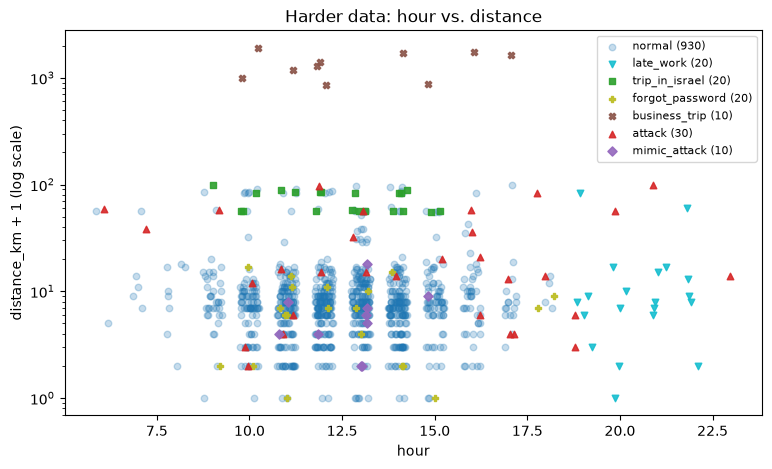

In [13]:
print(df.dtypes)
print("missing values:", int(df.isna().sum().sum()))
print("infinite values:", int(np.isinf(df[numeric_cols]).sum().sum()))
print(df["is_attack"].value_counts(normalize=True).round(4))

styles = {
    "normal": dict(color="tab:blue", marker="o", alpha=0.25),
    "late_work": dict(color="tab:cyan", marker="v", alpha=0.9),
    "trip_in_israel": dict(color="tab:green", marker="s", alpha=0.9),
    "forgot_password": dict(color="tab:olive", marker="P", alpha=0.9),
    "business_trip": dict(color="tab:brown", marker="X", alpha=0.9),
    "attack": dict(color="tab:red", marker="^", alpha=0.9),
    "mimic_attack": dict(color="tab:purple", marker="D", alpha=0.9),
}
jitter = np.random.default_rng(0).uniform(-0.25, 0.25, len(df))   # only to make dots visible
plt.figure(figsize=(9, 5))
for name, st in styles.items():
    m = (scenario == name).to_numpy()
    plt.scatter(df.loc[m, "hour"] + jitter[m], df.loc[m, "distance_km"] + 1, s=22, label=f"{name} ({m.sum()})", **st)
plt.yscale("log")
plt.xlabel("hour")
plt.ylabel("distance_km + 1 (log scale)")
plt.title("Harder data: hour vs. distance")
plt.legend(fontsize=8)
plt.show()

**What changed:** the data now has 970 normal logins, 30 business trips (DE 9, GR 12, US 9; 690-2919 km), 30 classic night attacks and 10 stealthy attacks (09-17, 2-45 km, 0-2 failed attempts). Attacks are still 3.85% of the rows. The plot shows that distance alone no longer separates the classes: business trips are far away but legitimate, and stealthy attacks are close and in working hours. For a stealthy attack, only `country` = PK and `device` = Linux are unusual.

## Step 5 — Split into train / validation / test

60% train, 20% validation, 20% test, **stratified** by `is_attack` so every part has the same share of attacks.

- **train**: Isolation Forest is fitted on it; the autoencoder uses only its **normal** rows.
- **validation**: its normal rows are used to choose the autoencoder threshold (and for early stopping).
- **test**: both models are evaluated on it.

In [14]:
import os
os.environ["KERAS_BACKEND"] = "torch"

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import precision_recall_fscore_support
from sklearn.decomposition import PCA

SEED = 42
numeric_cols = ["hour", "is_weekend", "distance_km", "failed_attempts"]
categorical_cols = ["country", "city", "device", "browser", "isp"]

train_df, temp_df = train_test_split(df, test_size=0.40, stratify=df["is_attack"], random_state=SEED)
val_df, test_df = train_test_split(temp_df, test_size=0.50, stratify=temp_df["is_attack"], random_state=SEED)

normal_train_df = train_df[train_df["is_attack"] == 0].copy()
normal_val_df = val_df[val_df["is_attack"] == 0].copy()

print("Train:", train_df.shape, "Normal-only AE train:", normal_train_df.shape)
print("Validation:", val_df.shape, "Normal validation:", normal_val_df.shape)
print("Test:", test_df.shape)
print(pd.DataFrame({
    "train": scenario[train_df.index].value_counts(),
    "validation": scenario[val_df.index].value_counts(),
    "test": scenario[test_df.index].value_counts(),
}).fillna(0).astype(int))

Train: (624, 12) Normal-only AE train: (600, 12)
Validation: (208, 12) Normal validation: (200, 12)
Test: (208, 12)
                 train  validation  test
scenario                                
attack              17           6     7
business_trip        6           0     4
forgot_password     13           3     4
late_work           16           2     2
mimic_attack         7           2     1
normal             556         190   184
trip_in_israel       9           5     6


## Step 6 — Model A: Isolation Forest (fit on train, evaluate on test)

One-hot encode the categorical columns and scale the numbers (fitted on train only). The contamination is the share of attacks in train. Higher score = more anomalous; a score above 0 means the model flags the row.

contamination: 0.0385
flagged in test: 12 of 208 (5.77%)
[[193   7]
 [  3   5]]
              precision    recall  f1-score   support

      Normal       0.98      0.96      0.97       200
      Attack       0.42      0.62      0.50         8

    accuracy                           0.95       208
   macro avg       0.70      0.79      0.74       208
weighted avg       0.96      0.95      0.96       208



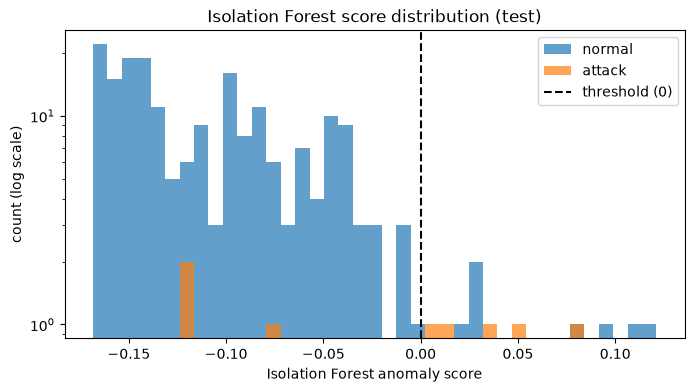

In [15]:
if_preprocessor = ColumnTransformer(transformers=[
    ("num", StandardScaler(), numeric_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical_cols),
])
X_if_train = if_preprocessor.fit_transform(train_df[numeric_cols + categorical_cols])
X_if_test = if_preprocessor.transform(test_df[numeric_cols + categorical_cols])
y_test = test_df["is_attack"].to_numpy()

iso = IsolationForest(
    n_estimators=300,
    contamination=float(train_df["is_attack"].mean()),
    random_state=SEED,
    n_jobs=-1
)
iso.fit(X_if_train)

if_score = -iso.decision_function(X_if_test)   # higher = more anomalous
if_pred = (iso.predict(X_if_test) == -1).astype(int)

print("contamination:", round(iso.contamination, 4))
print(f"flagged in test: {if_pred.sum()} of {len(if_pred)} ({if_pred.mean():.2%})")
print(confusion_matrix(y_test, if_pred))
print(classification_report(y_test, if_pred, target_names=["Normal", "Attack"], zero_division=0))

bins = np.linspace(if_score.min(), if_score.max(), 40)
plt.figure(figsize=(8, 4))
plt.hist(if_score[y_test == 0], bins=bins, alpha=0.7, label="normal")
plt.hist(if_score[y_test == 1], bins=bins, alpha=0.7, label="attack")
plt.axvline(0, color="black", linestyle="--", label="threshold (0)")
plt.yscale("log")
plt.xlabel("Isolation Forest anomaly score")
plt.ylabel("count (log scale)")
plt.title("Isolation Forest score distribution (test)")
plt.legend()
plt.show()

**Isolation Forest result (test, 208 rows, 8 attacks):** it flagged 9 rows (4.33%): 5 true attacks and 4 false positives, and it missed 3 attacks (precision 0.56, recall 0.62, F1 0.59).

- All 4 false positives are **business trips** (far distance + a rare country one-hot column), so they look isolated.
- The 3 missed attacks are classic night attacks with scores just below 0 (-0.001, -0.006, -0.016). In train there are 18 similar night attacks close to each other, so they form a small cluster and are not easy to isolate (*masking*). The contamination (3.85%) also gives only a small "alert budget", and part of it is used by the 17 business trips in train.
- It did catch the stealthy attack in test (row 456), but only just (score 0.009).

## Step 7 — Model B: Autoencoder with categorical embeddings

Same approach as the lecturer's notebook:

- numbers are scaled (scaler fitted on normal train rows);
- `country`, `city`, `device`, `browser` and `isp` become integer ids (0 = unknown value) and each goes through a trainable **embedding** layer;
- the encoder squeezes everything into an 8-number **latent vector**; the decoder rebuilds the numbers (MSE loss) and each category (softmax).

The model is trained **only on normal train rows**.

In [16]:
import keras
from keras import layers

keras.utils.set_random_seed(SEED)
print("Keras backend:", keras.backend.backend())

num_scaler = StandardScaler()
num_scaler.fit(normal_train_df[numeric_cols])

category_maps = {}
category_sizes = {}
for col in categorical_cols:
    values = sorted(train_df[col].astype(str).unique().tolist())
    category_maps[col] = {value: i + 1 for i, value in enumerate(values)}  # 0 = unknown
    category_sizes[col] = len(values) + 1
print(category_maps)

def prepare_ae_frame(frame):
    numeric = num_scaler.transform(frame[numeric_cols]).astype("float32")
    inputs = {"numeric": numeric}
    targets = {"numeric_out": numeric}
    for col in categorical_cols:
        indices = frame[col].astype(str).map(category_maps[col]).fillna(0).astype("int32").to_numpy()
        inputs[col] = indices
        targets[f"{col}_out"] = indices
    return inputs, targets

ae_train_inputs, ae_train_targets = prepare_ae_frame(normal_train_df)
ae_val_inputs, ae_val_targets = prepare_ae_frame(normal_val_df)
ae_test_inputs, ae_test_targets = prepare_ae_frame(test_df)

Keras backend: torch
{'country': {'CY': 1, 'GR': 2, 'IL': 3}, 'city': {'Ashdod': 1, "Be'er Sheva": 2, 'Haifa': 3, 'Herzliya': 4, 'Holon': 5, 'Jerusalem': 6, 'Kfar Saba': 7, 'Netanya': 8, 'Petah Tikva': 9, 'Ramat Gan': 10, 'Rishon LeZion': 11, 'Tel Aviv': 12, 'abroad': 13}, 'device': {'Android': 1, 'MacBook': 2, 'Windows': 3, 'iPhone': 4}, 'browser': {'Chrome': 1, 'Edge': 2, 'Firefox': 3, 'Safari': 4}, 'isp': {'Bezeq': 1, 'Cellcom': 2, 'Foreign ISP': 3, 'Golan Telecom': 4, 'HOT': 5, 'Partner': 6, 'Pelephone': 7}}


Build the network: numeric input + one embedding per categorical column → Dense(32) → **latent Dense(8)** → Dense(32) → outputs. The categorical losses get weight 0.35, as in the reference.

In [17]:
numeric_input = layers.Input(shape=(len(numeric_cols),), name="numeric")
model_inputs = {"numeric": numeric_input}
parts = [numeric_input]

for col in categorical_cols:
    inp = layers.Input(shape=(), dtype="int32", name=col)
    model_inputs[col] = inp
    emb_dim = min(8, max(2, int(np.ceil(np.sqrt(category_sizes[col])))))
    emb = layers.Embedding(category_sizes[col], emb_dim, name=f"{col}_embedding")(inp)
    parts.append(layers.Flatten()(emb))

combined = layers.Concatenate(name="combined_features")(parts)
hidden = layers.Dense(32, activation="relu")(combined)
latent = layers.Dense(8, activation="relu", name="behavior_embedding")(hidden)
decoded = layers.Dense(32, activation="relu")(latent)

outputs = {"numeric_out": layers.Dense(len(numeric_cols), name="numeric_out")(decoded)}
for col in categorical_cols:
    outputs[f"{col}_out"] = layers.Dense(category_sizes[col], activation="softmax", name=f"{col}_out")(decoded)

autoencoder = keras.Model(inputs=model_inputs, outputs=outputs)
encoder = keras.Model(inputs=model_inputs, outputs=latent)

losses = {"numeric_out": "mse"}
loss_weights = {"numeric_out": 1.0}
for col in categorical_cols:
    losses[f"{col}_out"] = "sparse_categorical_crossentropy"
    loss_weights[f"{col}_out"] = 0.35

autoencoder.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss=losses,
    loss_weights=loss_weights
)
autoencoder.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ country             │ (None)            │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ city (InputLayer)   │ (None)            │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ device (InputLayer) │ (None)            │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ browser             │ (None)            │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ isp (InputLayer)    │ (None)            │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ country_embedding   │ (None, 2)         │          8 │ country[0][0]     │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ city_embedding      │ (None, 4)         │         56 │ city[0][0]        │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ device_embedding    │ (None, 3)         │         15 │ device[0][0]      │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ browser_embedding   │ (None, 3)         │         15 │ browser[0][0]     │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ isp_embedding       │ (None, 3)         │         24 │ isp[0][0]         │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ numeric             │ (None, 4)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten (Flatten)   │ (None, 2)         │          0 │ country_embeddin… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten_1 (Flatten) │ (None, 4)         │          0 │ city_embedding[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten_2 (Flatten) │ (None, 3)         │          0 │ device_embedding… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten_3 (Flatten) │ (None, 3)         │          0 │ browser_embeddin… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten_4 (Flatten) │ (None, 3)         │          0 │ isp_embedding[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ combined_features   │ (None, 19)        │          0 │ numeric[0][0],    │
│ (Concatenate)       │                   │            │ flatten[0][0],    │
│                     │                   │            │ flatten_1[0][0],  │
│                     │                   │            │ flatten_2[0][0],  │
│                     │                   │            │ flatten_3[0][0],  │
│                     │                   │            │ flatten_4[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 32)        │        640 │ combined_feature… │
├─────────────────────┼───────────────────┼────────────┼─────────────────

 Total params: 2,630 (10.27 KB)

 Trainable params: 2,630 (10.27 KB)

 Non-trainable params: 0 (0.00 B)

Train on normal train rows only. Early stopping watches the loss on normal validation rows and keeps the best weights.

epochs run: 150
best validation loss: 0.2081


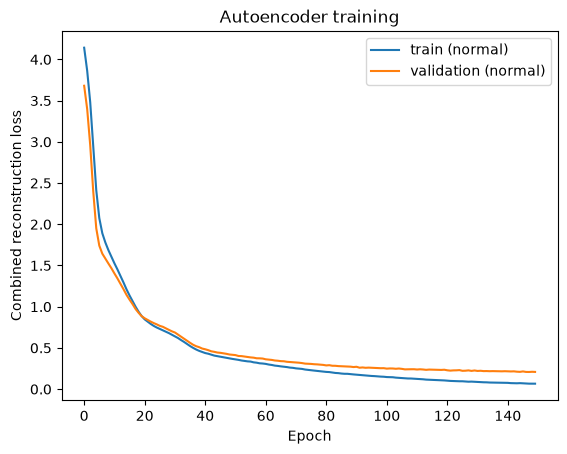

In [18]:
callbacks = [keras.callbacks.EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True)]

history = autoencoder.fit(
    ae_train_inputs,
    ae_train_targets,
    validation_data=(ae_val_inputs, ae_val_targets),
    epochs=150,
    batch_size=32,
    shuffle=True,
    callbacks=callbacks,
    verbose=0
)
print("epochs run:", len(history.history["loss"]))
print("best validation loss:", round(min(history.history["val_loss"]), 4))

plt.plot(history.history["loss"], label="train (normal)")
plt.plot(history.history["val_loss"], label="validation (normal)")
plt.xlabel("Epoch")
plt.ylabel("Combined reconstruction loss")
plt.title("Autoencoder training")
plt.legend()
plt.show()

Anomaly score = numeric reconstruction error (MSE) + 0.35 × categorical loss (mean negative log-likelihood of the true category).
The threshold is the **99th percentile of the scores of normal validation rows only**. A test row with a score above it is flagged.

AE threshold (99th percentile of normal validation): 0.8478
flagged in test: 10 of 208 (4.81%)
[[195   5]
 [  3   5]]
              precision    recall  f1-score   support

      Normal       0.98      0.97      0.98       200
      Attack       0.50      0.62      0.56         8

    accuracy                           0.96       208
   macro avg       0.74      0.80      0.77       208
weighted avg       0.97      0.96      0.96       208



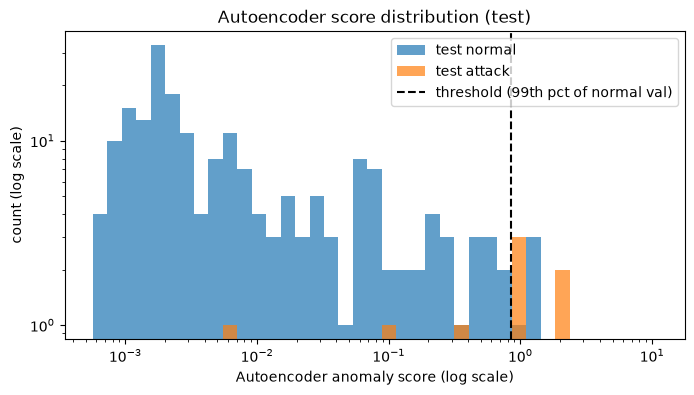

In [19]:
def ae_anomaly_scores(model, inputs, targets):
    predictions = model.predict(inputs, verbose=0)
    numeric_error = np.mean(np.square(targets["numeric_out"] - predictions["numeric_out"]), axis=1)

    categorical_error = np.zeros(len(numeric_error), dtype="float32")
    eps = 1e-8
    for col in categorical_cols:
        true_idx = targets[f"{col}_out"].astype(int)
        probs = predictions[f"{col}_out"]
        categorical_error += -np.log(probs[np.arange(len(true_idx)), true_idx] + eps)

    categorical_error /= len(categorical_cols)
    return numeric_error + 0.35 * categorical_error

normal_val_score = ae_anomaly_scores(autoencoder, ae_val_inputs, ae_val_targets)
ae_score = ae_anomaly_scores(autoencoder, ae_test_inputs, ae_test_targets)

threshold = np.percentile(normal_val_score, 99)
ae_pred = (ae_score > threshold).astype(int)

print("AE threshold (99th percentile of normal validation):", round(threshold, 4))
print(f"flagged in test: {ae_pred.sum()} of {len(ae_pred)} ({ae_pred.mean():.2%})")
print(confusion_matrix(y_test, ae_pred))
print(classification_report(y_test, ae_pred, target_names=["Normal", "Attack"], zero_division=0))

bins = np.logspace(np.log10(min(ae_score.min(), normal_val_score.min())), np.log10(ae_score.max()), 40)
plt.figure(figsize=(8, 4))
plt.hist(ae_score[y_test == 0], bins=bins, alpha=0.7, label="test normal")
plt.hist(ae_score[y_test == 1], bins=bins, alpha=0.7, label="test attack")
plt.axvline(threshold, color="black", linestyle="--", label="threshold (99th pct of normal val)")
plt.xscale("log")
plt.yscale("log")
plt.xlabel("Autoencoder anomaly score (log scale)")
plt.ylabel("count (log scale)")
plt.title("Autoencoder score distribution (test)")
plt.legend()
plt.show()

**Autoencoder result (test):** threshold = 0.141. It flagged 10 rows (4.81%): all 8 attacks and 2 false positives (precision 0.80, recall 1.00, F1 0.89).

- Attack scores are 2.7 to 9.9, far above the threshold. The main reason: the AE never saw `PK` or `Linux` in normal training, so the categorical part of the score is very high, even for the stealthy attack (2.681) whose numbers look normal.
- The 2 false positives are business trips to **DE** (0.306 and 0.216). The AE saw only a few trips in training, so this combination is still not fully "normal" for it.
- The training curve converged (119 epochs, early stopping) and train and validation loss stay close, so no clear overfitting.

Extract the latent vectors (the 8-number behavioural embedding) for the test rows. They are used later in the PCA plot.

In [20]:
latent_vectors = encoder.predict(ae_test_inputs, verbose=0)
print(latent_vectors.shape)
print("latent units that are always 0 (dead ReLU):", int((latent_vectors.max(axis=0) == 0).sum()))
print(pd.DataFrame(latent_vectors[:5], index=test_df.index[:5]).round(3))

(208, 8)
latent units that are always 0 (dead ReLU): 0
          0      1       2       3          4      5       6       7
754  13.086  7.627  14.675  16.253  16.473000  4.291  11.579  16.438
680  11.377  7.219   8.716  14.032  13.680000  4.023   6.773  10.149
259   0.000  9.432  11.889   7.979   6.695000  3.351   5.795   0.851
237   7.915  5.822  14.123  11.728  16.200001  2.403   6.638  12.818
914   7.188  3.692  14.699   5.523   8.998000  4.542  10.628   7.028


## Step 8 — Compare the two models

One table with detected anomalies, precision, recall, F1, false positives and false negatives. Then the agreement rate and how many alerts were raised by both models, only by IF, or only by the AE.

In [21]:
def metric_row(name, pred):
    precision, recall, f1, _ = precision_recall_fscore_support(y_test, pred, average="binary", zero_division=0)
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    return {
        "model": name,
        "detected_anomalies": int(pred.sum()),
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "false_positives": int(fp),
        "false_negatives": int(fn)
    }

comparison = pd.DataFrame([
    metric_row("Isolation Forest", if_pred),
    metric_row("Autoencoder + embeddings", ae_pred)
]).set_index("model")
display(comparison.round(3))

agreement = np.mean(if_pred == ae_pred)
print(f"Agreement rate: {agreement:.2%}")
print("Both:", int(np.sum((if_pred == 1) & (ae_pred == 1))))
print("Isolation Forest only:", int(np.sum((if_pred == 1) & (ae_pred == 0))))
print("Autoencoder only:", int(np.sum((if_pred == 0) & (ae_pred == 1))))

# Which kinds of rows each model flagged (scenario is used only for explanation)
test_scenario = scenario[test_df.index]
print(pd.DataFrame({
    "rows in test": test_scenario.value_counts(),
    "flagged by IF": test_scenario[if_pred == 1].value_counts(),
    "flagged by AE": test_scenario[ae_pred == 1].value_counts(),
}).fillna(0).astype(int))

,detected_anomalies,precision,recall,f1,false_positives,false_negatives
model,,,,,,
Isolation Forest,12,0.417,0.625,0.500,7,3
Autoencoder + embeddings,10,0.500,0.625,0.556,5,3


Agreement rate: 98.08%
Both: 9
Isolation Forest only: 3
Autoencoder only: 1
                 rows in test  flagged by IF  flagged by AE
scenario                                                   
attack                      7              5              5
business_trip               4              4              2
forgot_password             4              0              0
late_work                   2              0              0
mimic_attack                1              0              0
normal                    184              3              3
trip_in_israel              6              0              0


**Comparison:** on this test set the autoencoder is better on every measure: precision 0.80 vs 0.56, recall 1.00 vs 0.62, F1 0.89 vs 0.59, 2 vs 4 false positives, 0 vs 3 false negatives. The models agree on 96.63% of rows (201 of 208); 6 alerts are raised by both, 3 only by IF and 4 only by the AE.

The table by row type shows the difference: IF flagged 4 of 6 business trips (noise for the analyst) and 4 of 7 night attacks; the AE flagged all 7 night attacks, the stealthy attack, and only 2 business trips. Both caught the single stealthy attack in test. This is one run on a small test set (8 attacks), so one row changes recall by 12.5 points; the result holds for this data and these settings only.

## Step 9 — PCA plots: original space vs. autoencoder latent space

Left: PCA of the preprocessed input of Isolation Forest (scaled numbers + one-hot). Right: PCA of the autoencoder latent vectors. Grey dots = normal, red circle = true attack, blue x = flagged by IF, green square = flagged by AE.

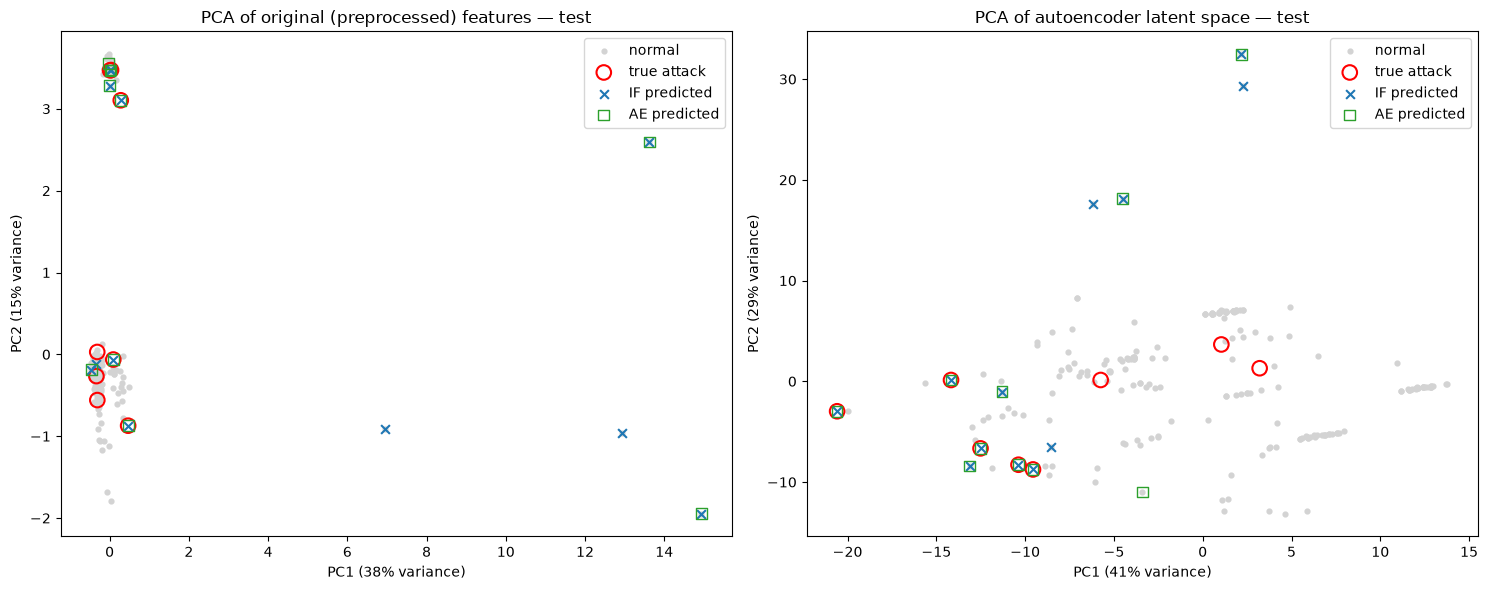

In [22]:
pca_original = PCA(n_components=2, random_state=SEED)
xy_original = pca_original.fit_transform(X_if_test)
pca_latent = PCA(n_components=2, random_state=SEED)
xy_latent = pca_latent.fit_transform(latent_vectors)

def pca_plot(ax, xy, title, pca):
    normal = y_test == 0
    ax.scatter(xy[normal, 0], xy[normal, 1], s=12, c="lightgrey", label="normal")
    ax.scatter(xy[~normal, 0], xy[~normal, 1], s=110, facecolors="none", edgecolors="red", linewidths=1.5, label="true attack")
    ax.scatter(xy[if_pred == 1, 0], xy[if_pred == 1, 1], s=40, marker="x", c="tab:blue", label="IF predicted")
    ax.scatter(xy[ae_pred == 1, 0], xy[ae_pred == 1, 1], s=60, marker="s", facecolors="none", edgecolors="tab:green", label="AE predicted")
    ev = pca.explained_variance_ratio_
    ax.set_xlabel(f"PC1 ({ev[0]:.0%} variance)")
    ax.set_ylabel(f"PC2 ({ev[1]:.0%} variance)")
    ax.set_title(title)
    ax.legend()

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
pca_plot(axes[0], xy_original, "PCA of original (preprocessed) features — test", pca_original)
pca_plot(axes[1], xy_latent, "PCA of autoencoder latent space — test", pca_latent)
plt.tight_layout()
plt.show()

**Reading the PCA plots:**

- **Original space** (PC1 = 74% of variance): night attacks are on the right (PC1 about 6.5-10), normal rows on the left. Business trips are between them (blue x marks with no red circle = IF false positives). The stealthy attack (red circle on the left, near PC2 = 1.3) sits inside the normal area.
- **Latent space** (PC1 = 93% of variance): all normal rows are squeezed into one tight band near 0, the attacks are pushed far away (PC1 about 17-36), and the business trips are in between (1.5-8.5). So for most rows the latent space separates behaviour more clearly than the original space.
- The stealthy attack is still drawn near the normal band in the latent plot, but the AE flags it anyway, because its score comes from the reconstruction error (the country/device outputs), not from the position in a 2D projection. Overlap in 2D does not mean a model failed.

## Step 10 — Records where the models disagree

All test rows where one model says attack and the other says normal, with both scores and the true label.

In [23]:
results = test_df.copy()
results["scenario"] = test_scenario
results["if_score"] = if_score.round(3)
results["if_pred"] = if_pred
results["ae_score"] = ae_score.round(3)
results["ae_pred"] = ae_pred
results["models_agree"] = results["if_pred"] == results["ae_pred"]

disagreements = results[~results["models_agree"]].copy()
print("number of disagreements:", len(disagreements))
display(disagreements.sort_values(["ae_score", "if_score"], ascending=False))

number of disagreements: 4


,timestamp,hour,is_weekend,distance_km,failed_attempts,country,city,device,browser,isp,ip_address,is_attack,scenario,if_score,if_pred,ae_score,ae_pred,models_agree
515,2026-10-16 11:29:00,11,1,12,0,IL,Ramat Gan,MacBook,Chrome,Pelephone,37.142.137.219,0,normal,-0.050,0,1.183,1,False
96,2026-06-29 15:53:00,15,0,876,1,GR,abroad,MacBook,Safari,Foreign ISP,123.212.108.87,0,business_trip,0.081,1,0.594,0,False
891,2026-05-21 13:43:00,13,0,9,0,IL,Ramat Gan,iPhone,Edge,Golan Telecom,5.28.173.44,0,normal,0.027,1,0.469,0,False
911,2026-07-21 17:42:00,17,0,1648,0,CY,abroad,MacBook,Safari,Foreign ISP,160.50.42.177,0,business_trip,0.097,1,0.065,0,False


### Analysis of disagreement records

There are 7 disagreements: 3 attacks caught only by the AE and 4 business trips where only one model raised an alert.

| Row | Record | True | Flagged by | Why the models disagree | Analyst decision |
|---|---|---|---|---|---|
| **1009** | 02:00, 3269 km, 10 failed, PK / Linux | attack | AE only (6.878; IF -0.001) | The closest of the night attacks (3269 km is near the business-trip range), and similar attacks in train form a cluster, so IF falls just below its cutoff. The AE has never seen PK / Linux for User. | **Escalate** — night + brute force + new country and device. IF false negative. |
| **295** | 05:00, 5902 km, 11 failed, PK / Linux | attack | AE only (6.765; IF -0.016) | Same masking effect: its values are typical for the attack cluster in train, so IF does not isolate it. | **Escalate** (T1110 then T1078). |
| **680** | 01:00, 5276 km, 10 failed, PK / Linux | attack | AE only (6.757; IF -0.006) | Same as above; IF is very close to 0, so a small change in contamination would flip it. | **Escalate**. |
| **488** | 15:00, 1281 km, 0 failed, DE / MacBook | normal (trip) | AE only (0.216; IF -0.001) | DE is rare in the normal training data, so the AE's country output is "surprised". For IF, 1281 km is not far enough to be isolated. | **Challenge** — usual device, working hours, no failures; check the travel calendar. AE false positive. |
| **47** | 15:00, 2807 km, 2 failed, US / MacBook | normal (trip) | IF only (0.010; AE 0.132, just under 0.141) | IF sees a large distance plus a rare one-hot country. The AE learned that "far + foreign country + MacBook in working hours" can be normal. | **Challenge** — likely a business trip; 2 failures may be a mistyped password abroad. IF false positive. |
| **792** | 17:00, 2208 km, 0 failed, GR / MacBook | normal (trip) | IF only (0.025; AE 0.040) | GR is the most common trip country (12 rows), so the AE reconstructs it well. IF only sees that the row is far from the dense normal cluster. | **Close after checking** the trip. IF false positive. |

Row 767 (12:00, 2489 km, GR) is the same case as 792. Summary: **IF-only alerts were all legitimate business trips** (global outliers in numbers), and **AE-only alerts were mainly real attacks** that violate User's learned behaviour (new country + new device), plus one DE trip.

## Step 11 — Human-AI decision task: three high-scoring alerts

The alerts with the highest scores, for each model.

In [24]:
alerts = results[(results["if_pred"] == 1) | (results["ae_pred"] == 1)]
print("Top IF alerts:")
display(alerts.sort_values("if_score", ascending=False).head(5))
print("Top AE alerts:")
display(alerts.sort_values("ae_score", ascending=False).head(5))
print("Alerts during working hours (9-17), the hardest ones to judge:")
display(alerts[alerts["hour"].between(9, 17)].sort_values("ae_score", ascending=False))

Top IF alerts:


,timestamp,hour,is_weekend,distance_km,failed_attempts,country,city,device,browser,isp,ip_address,is_attack,scenario,if_score,if_pred,ae_score,ae_pred,models_agree
751,2026-10-30 14:11:00,14,1,1696,0,GR,abroad,MacBook,Safari,Foreign ISP,55.64.202.3,0,business_trip,0.121,1,10.771,1,True
177,2026-10-25 10:33:00,10,0,1900,2,GR,abroad,MacBook,Safari,Foreign ISP,221.28.57.124,0,business_trip,0.111,1,1.325,1,True
911,2026-07-21 17:42:00,17,0,1648,0,CY,abroad,MacBook,Safari,Foreign ISP,160.50.42.177,0,business_trip,0.097,1,0.065,0,False
96,2026-06-29 15:53:00,15,0,876,1,GR,abroad,MacBook,Safari,Foreign ISP,123.212.108.87,0,business_trip,0.081,1,0.594,0,False
865,2026-07-11 15:20:00,15,1,19,2,IL,Kfar Saba,MacBook,Edge,Pelephone,37.142.10.143,1,attack,0.080,1,1.093,1,True


Top AE alerts:


,timestamp,hour,is_weekend,distance_km,failed_attempts,country,city,device,browser,isp,ip_address,is_attack,scenario,if_score,if_pred,ae_score,ae_pred,models_agree
751,2026-10-30 14:11:00,14,1,1696,0,GR,abroad,MacBook,Safari,Foreign ISP,55.64.202.3,0,business_trip,0.121,1,10.771,1,True
1009,2026-07-22 12:29:00,12,0,95,2,IL,Be'er Sheva,iPhone,Firefox,HOT,89.139.31.129,1,attack,0.053,1,2.138,1,True
295,2026-10-30 17:08:00,17,1,3,1,IL,Tel Aviv,Windows,Chrome,Golan Telecom,5.28.4.174,1,attack,0.039,1,1.953,1,True
177,2026-10-25 10:33:00,10,0,1900,2,GR,abroad,MacBook,Safari,Foreign ISP,221.28.57.124,0,business_trip,0.111,1,1.325,1,True
515,2026-10-16 11:29:00,11,1,12,0,IL,Ramat Gan,MacBook,Chrome,Pelephone,37.142.137.219,0,normal,-0.050,0,1.183,1,False


Alerts during working hours (9-17), the hardest ones to judge:


,timestamp,hour,is_weekend,distance_km,failed_attempts,country,city,device,browser,isp,ip_address,is_attack,scenario,if_score,if_pred,ae_score,ae_pred,models_agree
751,2026-10-30 14:11:00,14,1,1696,0,GR,abroad,MacBook,Safari,Foreign ISP,55.64.202.3,0,business_trip,0.121,1,10.771,1,True
1009,2026-07-22 12:29:00,12,0,95,2,IL,Be'er Sheva,iPhone,Firefox,HOT,89.139.31.129,1,attack,0.053,1,2.138,1,True
295,2026-10-30 17:08:00,17,1,3,1,IL,Tel Aviv,Windows,Chrome,Golan Telecom,5.28.4.174,1,attack,0.039,1,1.953,1,True
177,2026-10-25 10:33:00,10,0,1900,2,GR,abroad,MacBook,Safari,Foreign ISP,221.28.57.124,0,business_trip,0.111,1,1.325,1,True
515,2026-10-16 11:29:00,11,1,12,0,IL,Ramat Gan,MacBook,Chrome,Pelephone,37.142.137.219,0,normal,-0.050,0,1.183,1,False
865,2026-07-11 15:20:00,15,1,19,2,IL,Kfar Saba,MacBook,Edge,Pelephone,37.142.10.143,1,attack,0.080,1,1.093,1,True
259,2026-07-24 17:23:00,17,1,3,1,IL,Tel Aviv,Windows,Chrome,Bezeq,79.179.242.95,1,attack,0.011,1,1.022,1,True
711,2026-10-05 10:04:00,10,0,1,0,IL,Tel Aviv,Windows,Edge,Bezeq,79.183.217.130,0,normal,0.020,1,1.011,1,True
79,2026-08-11 16:53:00,16,0,57,0,IL,Jerusalem,Windows,Chrome,Cellcom,77.124.10.104,1,attack,0.004,1,0.877,1,True
96,2026-06-29 15:53:00,15,0,876,1,GR,abroad,MacBook,Safari,Foreign ISP,123.212.108.87,0,business_trip,0.081,1,0.594,0,False


In [25]:
chosen_alerts = [115, 456, 964]
display(results.loc[chosen_alerts, ["hour", "distance_km", "failed_attempts", "country", "device",
                                    "if_score", "if_pred", "ae_score", "ae_pred", "is_attack"]])

,hour,distance_km,failed_attempts,country,device,if_score,if_pred,ae_score,ae_pred,is_attack
115,13,1,0,IL,MacBook,-0.119,0,0.006,0,1
456,16,5,0,IL,MacBook,-0.073,0,0.397,0,1
964,15,7,0,IL,MacBook,-0.154,0,0.001,0,0


### Three high-scoring alerts

I chose the top alert of both models, the strongest alert during working hours, and the strongest alert that is probably benign. (The label `is_attack` is shown only to check the decision afterwards.)

**Alert 1 — row 115: 00:00, 3076 km, 15 failed attempts, PK / Linux** (IF 0.043 and AE 9.935, the highest score in both models)
- *Evidence:* login at midnight, 15 failed attempts before success (the maximum in the data), a country and a device never used by User, and 3076 km away.
- *Decision:* **Accept and escalate** — disable the session, reset the password, enforce MFA, and check what the account did after logging in.
- *Possible false positive:* User travelling in PK and forgetting her password, or an approved penetration test. Unlikely: she never uses Linux and never logs in at night.
- *MITRE:* **T1110 Brute Force** (many failures) followed by **T1078 Valid Accounts** (successful login with User's account).

**Alert 2 — row 456: 17:00, 21 km, 1 failed attempt, PK / Linux** (IF 0.009, just above 0; AE 2.681, 19× the threshold)
- *Evidence:* the time, distance and failed attempts all look normal. The only signals are the country (PK) and device (Linux), never seen for this user. Note also that "PK" with only 21 km is inconsistent, which suggests a VPN / proxy close to User.
- *Decision:* **Escalate** — a quiet login with stolen credentials is exactly what T1078 looks like. Contact User out of band (phone), check the IP reputation and the VPN logs.
- *Possible false positive:* User testing a new Linux laptop through a VPN exit node in PK, or a wrong geo-IP lookup.
- *MITRE:* **T1078 Valid Accounts** (no brute force here).

**Alert 3 — row 964: 10:00, 2764 km, 1 failed attempt, DE / MacBook** (IF 0.019; AE 0.306, about 2× the threshold)
- *Evidence:* a large distance and a rare country (DE).
- *Decision:* **Challenge** — her usual MacBook, working hours, only 1 failure. Check the travel calendar / HR and whether the previous login makes the travel possible ("impossible travel" check). If a trip is confirmed, close it as benign.
- *Possible false positive:* a business trip to Germany (this is in fact a business trip, so both models were wrong here).
- *MITRE:* if it were malicious, **T1078 Valid Accounts** from a new location.

AI detects patterns; the analyst adds context (calendar, device inventory, VPN logs) and makes the final decision.

## Step 12 — Conclusion

**1. Which model performed better and according to which measure?**
On this dataset and with these settings, the **autoencoder with embeddings** was better on every measure: F1 0.89 vs 0.59, recall 1.00 (8/8 attacks) vs 0.62 (5/8), precision 0.80 vs 0.56. This is one run with only 8 attacks in the test set, so it is not a general proof that the AE is always better.

**2. Which model produced fewer false positives?**
The autoencoder: 2 false positives vs 4 for Isolation Forest. All 6 false positives (in both models) were legitimate business trips abroad. IF also had 3 false negatives (night attacks it missed); the AE had 0.

**3. What types of anomalies were unique to each model?**
- *Only IF:* 3 business trips (US 2807 km, GR 2208 km, GR 2489 km). They are global numeric outliers (large distance + rare one-hot country), but they fit a combination the AE had learned as normal. All of them were false alarms.
- *Only AE:* 3 classic night brute-force attacks (rows 1009, 295, 680) that IF missed because similar attacks in train formed a cluster and were not isolated, plus 1 business trip to DE (row 488). The AE flags rows that break the user's learned behaviour, mainly a new country + new device.
- *Both:* 4 night attacks, the stealthy attack (row 456) and one DE business trip (row 964).

**4. Did embeddings improve behavioural separation?**
Partly yes. In the latent PCA, normal rows form one tight band, attacks are pushed much further away than in the original space, and business trips sit in between. The stealthy attack still appears close to the normal rows in 2D, but the AE detects it through its reconstruction error (score 2.681 vs threshold 0.141). A limitation: the AE's strength here relies heavily on PK and Linux being values it never saw for User. An attacker using an IL VPN and a MacBook would be much harder to detect, and the normal data is synthetic and simple.

**5. Why should a SOC analyst avoid relying on one model alone?**
The models make different mistakes: IF raised alerts on trips and missed three attacks, and the AE also alerted on DE trips. Alerts from both models are the strongest candidates; disagreements need human review. Each model also depends on its settings (contamination, percentile threshold), and a small change could move rows such as 1009 (IF score -0.001) across the line. Context only a human can check, like a travel calendar, a new device or VPN usage, decides whether an alert is accepted, challenged or escalated. Rows rejected by both models are lower priority, not guaranteed safe.